In [3]:
import torch
from anemone.experiment import Loop, Receiver
from anemone.physics import hzdt_halfspace_center_circle_loop
from anemone import constants as c
from anemone.forwards import *
from anemone.physics import rte_halfspace

In [25]:
class ForwardCentralCircle2(BaseForward):
    def __init__(self, radius, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        tx,rx = Loop.circle(radius), Receiver()
        super().__init__(tx, rx, times, waveform, filterfunc, t_gatewidth, tolerance)
        self.tx_radius = torch.tensor(radius, dtype=torch.double)
        self.device = times.device
        self.rte = []
        # self.primary = torch.nan_to_num(self.calc_primary())

    # def calc_primary(self):
    #     def f_integrand(f):
    #         self.omega = 2.*torch.pi*f[None, :, None]
    #         def wvlngth_integrand(wave_length):
    #             self.lmb = wave_length[None, None, :]
    #             intg = (1.+0j)*self.lmb
    #             return intg
    #         hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, device=self.device)
    #         hkl1._recenter_function(self.tx_radius)
    #         return ((hkl1.func(hkl1.lamda))@(hkl1.fc+0j))/2.
    #     ift = invFourier(f_integrand, smp_per_decade = 16, range=(self.tmin, self.tmax), device=self.device)
    #     self.tc = ift.rc        
    #     primary = ift(self.times)
    #     return primary

    def forward(self):
        def f_integrand(f):
            self.omega = 2.*torch.pi*f[None, :, None]
            def wvlngth_integrand(wave_length):
                self.lmb = wave_length[None, None, :]
                self.rte=rte_halfspace(self.sigma, self.omega, self.lmb)
                intg = self.rte*self.lmb
                return intg
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, device=self.device)
            hkl1._recenter_function(self.tx_radius)
            return ((hkl1.func(hkl1.lamda))@(hkl1.fc+0j))/2.

        ift = invFourier(f_integrand, smp_per_decade = 16, device=self.device)
        self.tc = ift.rc        
        dbdts = ift(self.times)
        return dbdts

    def __call__(self, rho):
        self.rho = rho[:, None, None]
        return self.forward()*c.mu0

In [74]:
class Forward2(BaseForward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
        self.t2t = None

    def forward_halfspace(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb / c.fourpi
                self.rte_halfspace = rte_halfspace(self.sigma[:1], self.omega, self.lmb)
                intg = self.rte_halfspace*self.sfield_rte
                return intg.squeeze()
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        cbft=invFourier(frq_integrand, device=self.device, range=(self.tmin, self.tmax), tolerance=self.tolerance)
        if self.t2t is None:
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = cbft.preintegrate(t2t_func, self.tmin, self.tmax)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        return Ht


    def forward(self):
        self.d_halfspace = self.forward_halfspace()
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                rte_minus_halfspace = rte(self.sigma, self.thick, self.omega, self.lmb) - self.rte_halfspace
                intg = rte_minus_halfspace*self.sfield_rte
                return intg.squeeze()
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        self.cbft=invFourier(frq_integrand, device=self.device, range=(self.tmin, self.tmax), tolerance=self.tolerance)
        if self.t2t is None:    
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        return self.d_halfspace
        
    def __call__(self, rho, thickness, jac=False):
        self.rho = ((rho+0j)[..., None, None])#.to(self.device)
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = ((thickness+0j)[..., None, None])#.to(self.device)
        return self.forward()*c.mu0

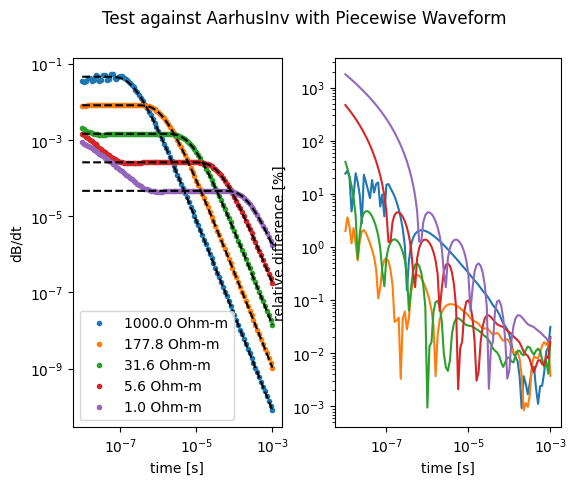

In [75]:
ForwardMaker = ForwardCentralCircle2

name = ForwardMaker.__name__
radius = 40.
lp = Loop.circle(radius, n=64)
# lp = Loop.square((c.pi*radius*radius)**(1/2))
rx = Receiver()
times = torch.logspace(-8, -3, 101, dtype=torch.double)

rho = torch.logspace(3, 0, 5, dtype=torch.double)

# fwr = Forward2(lp, rx, times)
fwr = ForwardMaker(radius, times)
# dbdt = fwr(rho, thick)
dbdt = fwr(rho).real.T

dbdt_analytic = hzdt_halfspace_center_circle_loop(times[:, None], rho[None, :], radius).real*c.mu0

   
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True)
ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
ax[0].set_ylabel('dB/dt')
ax[0].set_aspect('equal')

ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
ax[1].set_ylabel('relative difference [%]')
# ax[1].set_ylim(None, 1e3)
for ax_ in ax:
    ax_.set_xlabel('time [s]')
ax[0].legend([f'{r:.1f} Ohm-m' for r in rho.numpy()], loc='lower left')

fig.suptitle('Test against AarhusInv with Piecewise Waveform')
plt.show()

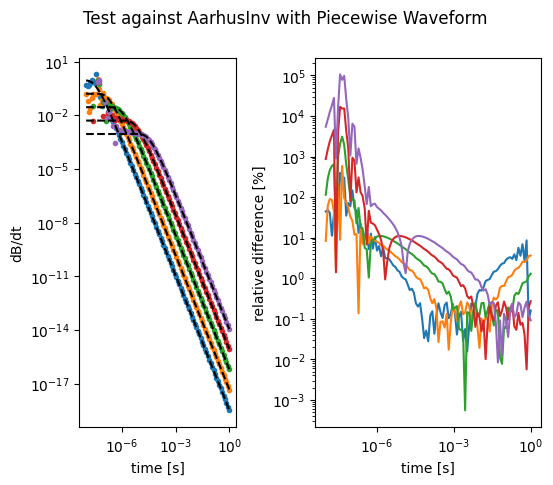

In [76]:
ForwardMaker = Forward2

from anemone.experiment import Loop, Receiver
from anemone.physics import hzdt_halfspace_center_circle_loop
from anemone import constants as c
name = ForwardMaker.__name__
radius = 15
lp = Loop.circle(radius, n=64)
# lp = Loop.square((c.pi*radius*radius)**(1/2))
rx = Receiver(z=1.)
times = torch.logspace(-8, 0, 101, dtype=torch.double)

rho = torch.logspace(3, 0, 5, dtype=torch.double)[None, :]*torch.ones(3, dtype=torch.double)[:, None]
thick = torch.ones(2, dtype=torch.double)*20

fwr = ForwardMaker(lp, rx, times)
dbdt = fwr(rho, thick).real.T

dbdt_analytic = hzdt_halfspace_center_circle_loop(times[:, None], rho[None, 0, :], radius).real*c.mu0

import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True)
ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
ax[0].set_ylabel('dB/dt')
ax[0].set_aspect('equal')

ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
ax[1].set_ylabel('relative difference [%]')
# ax[1].set_ylim(None, 1e3)
for ax_ in ax:
    ax_.set_xlabel('time [s]')

fig.suptitle('Test against AarhusInv with Piecewise Waveform')
plt.show()